### Embedding distances

The primary metric will be the paired Euclidean distance between the “clean” embedding and the “defective” embedding of the same unit. As a secondary metric, this project will report cosine similarity, because it is easy to interpret semantically. In addition, we will record the percentage of pairs with zero displacement, because Over-Polished has already shown that this can reveal blind spots in the representation.

Important: MiniLMs are normalized to norm 1, so Euclidean distance and cosine similarity are mathematically related:

$$ \|x-y\|_2^2 = 2(1-\cos(x,y)). $$

They will not be treated as two separate metrics. Euclidean distance will be the primary metric; cosine similarity will simply help us intuitively explain the extent to which the semantic direction is preserved.

**The main question to answer is: How strongly does the representation itself react to the injected defect?**

In [8]:
import importlib
import numpy as np
import pandas as pd

import src.paths as paths
import src.io_utils as io_utils
import src.representations as representations


In [9]:
importlib.reload(paths)
importlib.reload(io_utils)
importlib.reload(representations)


from src.paths import (
    get_project_paths
)

from src.io_utils import (
    load_embedding_conditions,
    load_id_file,
    load_affected_ids_by_severity
)


PATHS = get_project_paths()

ROOT = PATHS["root"]
DATA_DIR = PATHS["processed"]
RESULTS_DIR = PATHS["results"]

WEEK7_RESULTS_DIR = (
    RESULTS_DIR
    / "week7"
)

WEEK7_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "Project root:",
    ROOT
)

print(
    "Processed data:",
    DATA_DIR
)

print(
    "Week 7 results:",
    WEEK7_RESULTS_DIR
)

Project root: /Users/jessica/fidelity-metric-lab
Processed data: /Users/jessica/fidelity-metric-lab/data/processed
Week 7 results: /Users/jessica/fidelity-metric-lab/results/week7


In [10]:
# experiments registry 
EXPERIMENTS = {

    "Entity Inconsistency": {

        "prefix":
            "entity",

        "id_file":
            "entity_embedding_campaign_ids.csv",

        "affected_file":
            "entity_inconsistency_affected_campaign_ids.csv",

        "id_column":
            "campaign_id",

        "unit":
            "campaign",

        "power_file":
            "entity_inconsistency_power_summary.csv"
    },


    "Missing Cross-Channel Reference": {

        "prefix":
            "missing_reference",

        "id_file":
            "missing_reference_embedding_campaign_ids.csv",

        "affected_file":
            "missing_reference_affected_campaign_ids.csv",

        "id_column":
            "campaign_id",

        "unit":
            "campaign",

        "power_file":
            "missing_cross_channel_power_summary.csv"
    },


    "Over-Polished Language": {

        "prefix":
            "over_polished",

        "id_file":
            "over_polished_embedding_message_ids.csv",

        "affected_file":
            "over_polished_affected_message_ids.csv",

        "id_column":
            "message_id",

        "unit":
            "message",

        "power_file":
            "over_polished_semantic_power_summary.csv"
    }
}


SEVERITIES = [
    0.10,
    0.30,
    0.60
]

In [13]:
importlib.reload(
    representations
)

from src.representations import (
    paired_embedding_distance_table,
    summarize_embedding_distance_table
)

In [41]:
# load processed data from previous experiments 
experiment_data = {}


for defect, config in (
    EXPERIMENTS.items()
):

    print(
        f"\nLoading: {defect}"
    )

    embeddings = (
        load_embedding_conditions(
            DATA_DIR,
            prefix=config[
                "prefix"
            ]
        )
    )


    ids = load_id_file(
        DATA_DIR,
        filename=config[
            "id_file"
        ],
        id_column=config[
            "id_column"
        ]
    )


    affected_ids = (
        load_affected_ids_by_severity(
            DATA_DIR
            / config[
                "affected_file"
            ],
            id_column=config[
                "id_column"
            ]
        )
    )


    power = pd.read_csv(
        RESULTS_DIR
        / config[
            "power_file"
        ]
    )


    experiment_data[
        defect
    ] = {
        "embeddings":
            embeddings,

        "ids":
            ids,

        "affected_ids":
            affected_ids,

        "power":
            power
    }


    print(
        "IDs:",
        len(ids)
    )

    for condition, X in (
        embeddings.items()
    ):

        print(
            condition,
            X.shape
        )


Loading: Entity Inconsistency
IDs: 300
clean (300, 384)
0.1 (300, 384)
0.3 (300, 384)
0.6 (300, 384)

Loading: Missing Cross-Channel Reference
IDs: 300
clean (300, 384)
0.1 (300, 384)
0.3 (300, 384)
0.6 (300, 384)

Loading: Over-Polished Language
IDs: 300
clean (300, 384)
0.1 (300, 384)
0.3 (300, 384)
0.6 (300, 384)


In [42]:
# embedding distances calculation 
pairwise_distance_tables = {}

summary_records = []


for defect, data in (
    experiment_data.items()
):

    clean = (
        data[
            "embeddings"
        ]["clean"]
    )

    ids = data[
        "ids"
    ]


    for severity in (
        SEVERITIES
    ):

        defective = (
            data[
                "embeddings"
            ][severity]
        )

        affected_ids = (
            data[
                "affected_ids"
            ][severity]
        )


        distance_df = (
            paired_embedding_distance_table(
                unit_ids=ids,
                clean_embeddings=clean,
                defective_embeddings=(
                    defective
                ),
                affected_ids=(
                    affected_ids
                ),
                tolerance=1e-8
            )
        )


        distance_df.insert(
            0,
            "defect",
            defect
        )

        distance_df.insert(
            1,
            "severity",
            severity
        )


        pairwise_distance_tables[
            (
                defect,
                severity
            )
        ] = distance_df


        # -------------------------------------
        # All pairs
        # -------------------------------------

        all_summary = (
            summarize_embedding_distance_table(
                distance_df,
                affected_only=False
            )
        )

        all_summary.update({
            "defect":
                defect,

            "severity":
                severity,

            "subset":
                "all"
        })

        summary_records.append(
            all_summary
        )


        # -------------------------------------
        # Affected pairs only
        # -------------------------------------

        affected_summary = (
            summarize_embedding_distance_table(
                distance_df,
                affected_only=True
            )
        )

        affected_summary.update({
            "defect":
                defect,

            "severity":
                severity,

            "subset":
                "affected"
        })

        summary_records.append(
            affected_summary
        )


embedding_distance_summary = (
    pd.DataFrame(
        summary_records
    )
)

In [43]:
# pair-wise observations 
embedding_distance_pairwise = (
    pd.concat(
        pairwise_distance_tables.values(),
        ignore_index=True
    )
)


print(
    "Pair-level rows:",
    len(
        embedding_distance_pairwise
    )
)


display(
    embedding_distance_pairwise.head()
)

Pair-level rows: 2700


,defect,severity,unit_id,euclidean_distance,cosine_similarity,cosine_distance,zero_displacement,affected
0,Entity Inconsistency,0.1,C0003,0.0,1.0,0.0,True,False
1,Entity Inconsistency,0.1,C0004,0.0,1.0,0.0,True,False
2,Entity Inconsistency,0.1,C0006,0.0,1.0,0.0,True,False
3,Entity Inconsistency,0.1,C0008,0.0,1.0,0.0,True,False
4,Entity Inconsistency,0.1,C0010,0.0,1.0,0.0,True,False


In [44]:
# unaffected sanity check 
unaffected_validation = (
    embedding_distance_pairwise[
        ~embedding_distance_pairwise[
            "affected"
        ]
    ]
    .groupby(
        [
            "defect",
            "severity"
        ]
    )[
        "euclidean_distance"
    ]
    .agg(
        [
            "mean",
            "max"
        ]
    )
)


display(
    unaffected_validation
)

mean  max
defect                          severity           
Entity Inconsistency            0.1        0.0  0.0
                                0.3        0.0  0.0
                                0.6        0.0  0.0
Missing Cross-Channel Reference 0.1        0.0  0.0
                                0.3        0.0  0.0
                                0.6        0.0  0.0
Over-Polished Language          0.1        0.0  0.0
                                0.3        0.0  0.0
                                0.6        0.0  0.0

In [45]:
# affected only metric summary
affected_summary = (
    embedding_distance_summary[
        embedding_distance_summary[
            "subset"
        ]
        ==
        "affected"
    ]
    .copy()
)


display(
    affected_summary[
        [
            "defect",
            "severity",
            "n_pairs",
            "mean_distance",
            "median_distance",
            "std_distance",
            "q25_distance",
            "q75_distance",
            "max_distance",
            "mean_cosine_similarity",
            "zero_displacement_count",
            "zero_displacement_rate"
        ]
    ]
)

,defect,severity,n_pairs,mean_distance,median_distance,std_distance,q25_distance,q75_distance,max_distance,mean_cosine_similarity,zero_displacement_count,zero_displacement_rate
1,Entity Inconsistency,0.1,30,0.063403,0.062811,0.022338,0.046239,0.077756,0.122291,0.997741,0,0.000000
3,Entity Inconsistency,0.3,90,0.059693,0.054587,0.027085,0.043035,0.069831,0.220437,0.997852,0,0.000000
5,Entity Inconsistency,0.6,180,0.058461,0.054144,0.024268,0.042940,0.069261,0.220437,0.997997,0,0.000000
7,Missing Cross-Channel Reference,0.1,30,0.159332,0.128931,0.116056,0.087950,0.163227,0.521489,0.980572,0,0.000000
9,Missing Cross-Channel Reference,0.3,90,0.136995,0.115084,0.086208,0.086182,0.148999,0.521489,0.986900,0,0.000000
11,Missing Cross-Channel Reference,0.6,180,0.140151,0.118751,0.084180,0.091373,0.157707,0.521489,0.986636,0,0.000000
13,Over-Polished Language,0.1,30,0.189858,0.164287,0.093430,0.115199,0.267630,0.380945,0.977612,0,0.000000
15,Over-Polished Language,0.3,90,0.202803,0.166639,0.156932,0.112359,0.249659,1.086167,0.967122,2,0.022222
17,Over-Polished Language,0.6,180,0.206644,0.166639,0.159206,0.111838,0.267337,1.114274,0.965976,7,0.038889


In [46]:
affected_summary = (
    embedding_distance_summary[
        embedding_distance_summary[
            "subset"
        ]
        ==
        "affected"
    ]
    .reset_index(drop=True)
)

In [47]:
# known-answer validation 
over_polished_check = (
    affected_summary[
        affected_summary[
            "defect"
        ]
        ==
        "Over-Polished Language"
    ][
        [
            "severity",
            "mean_distance",
            "median_distance",
            "mean_cosine_similarity",
            "zero_displacement_count"
        ]
    ]
)


display(
    over_polished_check
)

,severity,mean_distance,median_distance,mean_cosine_similarity,zero_displacement_count
6,0.1,0.189858,0.164287,0.977612,0
7,0.3,0.202803,0.166639,0.967122,2
8,0.6,0.206644,0.166639,0.965976,7


In [48]:
# save results 
embedding_distance_pairwise.to_csv(
    WEEK7_RESULTS_DIR
    / "embedding_distances_pairwise.csv",
    index=False
)


embedding_distance_summary.to_csv(
    WEEK7_RESULTS_DIR
    / "embedding_distances_summary.csv",
    index=False
)


print(
    "Week 7 embedding-distance "
    "results saved."
)

Week 7 embedding-distance results saved.


In [49]:
# combine distances with power 
power_frames = []


for defect, data in (
    experiment_data.items()
):

    power = (
        data[
            "power"
        ][
            [
                "severity",
                "metric",
                "power"
            ]
        ]
        .copy()
    )

    power[
        "defect"
    ] = defect

    power_frames.append(
        power
    )


combined_power = (
    pd.concat(
        power_frames,
        ignore_index=True
    )
)


display(
    combined_power.head()
)

,severity,metric,power,defect
0,0.1,C2ST,0.000,Entity Inconsistency
1,0.1,Energy,0.605,Entity Inconsistency
2,0.1,MMD,0.640,Entity Inconsistency
3,0.3,C2ST,0.025,Entity Inconsistency
4,0.3,Energy,1.000,Entity Inconsistency


In [50]:
# merge with affected embedding distance
distance_vs_power = (
    affected_summary[
        [
            "defect",
            "severity",
            "mean_distance",
            "median_distance",
            "std_distance",
            "mean_cosine_similarity",
            "zero_displacement_rate"
        ]
    ]
    .merge(
        combined_power,
        on=[
            "defect",
            "severity"
        ],
        how="left"
    )
)


display(
    distance_vs_power
)

,defect,severity,mean_distance,median_distance,std_distance,mean_cosine_similarity,zero_displacement_rate,metric,power
0,Entity Inconsistency,0.1,0.063403,0.062811,0.022338,0.997741,0.000000,C2ST,0.000
1,Entity Inconsistency,0.1,0.063403,0.062811,0.022338,0.997741,0.000000,Energy,0.605
2,Entity Inconsistency,0.1,0.063403,0.062811,0.022338,0.997741,0.000000,MMD,0.640
3,Entity Inconsistency,0.3,0.059693,0.054587,0.027085,0.997852,0.000000,C2ST,0.025
4,Entity Inconsistency,0.3,0.059693,0.054587,0.027085,0.997852,0.000000,Energy,1.000
5,Entity Inconsistency,0.3,0.059693,0.054587,0.027085,0.997852,0.000000,MMD,1.000
6,Entity Inconsistency,0.6,0.058461,0.054144,0.024268,0.997997,0.000000,C2ST,0.165
7,Entity Inconsistency,0.6,0.058461,0.054144,0.024268,0.997997,0.000000,Energy,1.000
8,Entity Inconsistency,0.6,0.058461,0.054144,0.024268,0.997997,0.000000,MMD,1.000
9,Missing Cross-Channel Reference,0.1,0.159332,0.128931,0.116056,0.980572,0.000000,C2ST,0.005


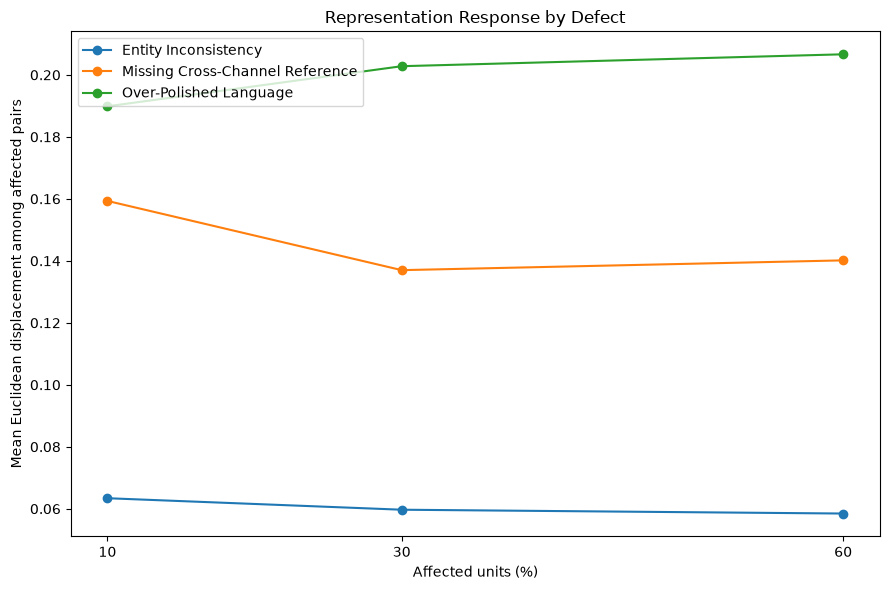

In [51]:
# representation response
import matplotlib.pyplot as plt


plt.figure(
    figsize=(9, 6)
)


for defect in (
    affected_summary[
        "defect"
    ].unique()
):

    subset = (
        affected_summary[
            affected_summary[
                "defect"
            ]
            ==
            defect
        ]
        .sort_values(
            "severity"
        )
    )


    plt.plot(
        subset[
            "severity"
        ] * 100,

        subset[
            "mean_distance"
        ],

        marker="o",
        label=defect
    )


plt.xlabel(
    "Affected units (%)"
)

plt.ylabel(
    "Mean Euclidean displacement "
    "among affected pairs"
)

plt.title(
    "Representation Response by Defect"
)

plt.xticks(
    [
        10,
        30,
        60
    ]
)

plt.legend()

plt.tight_layout()

plt.show()

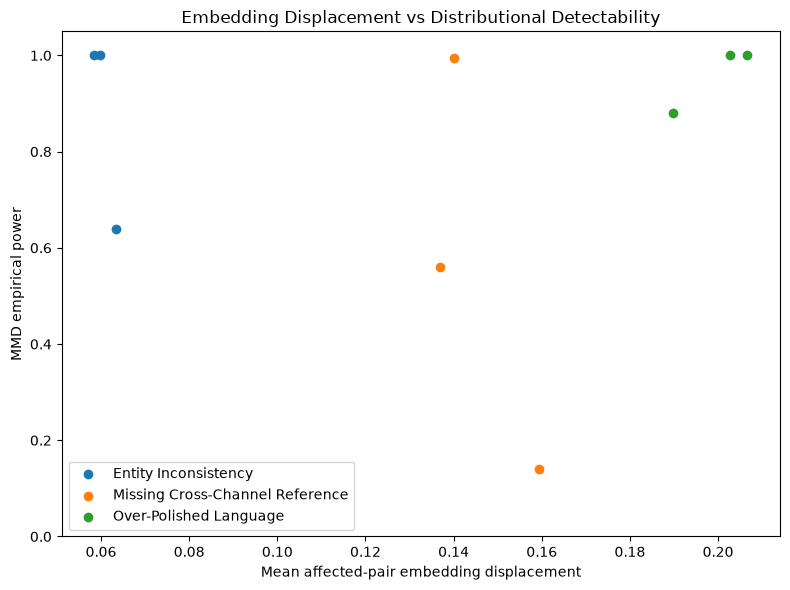

In [52]:
# distance vs power mmd 
mmd_comparison = (
    distance_vs_power[
        distance_vs_power[
            "metric"
        ]
        ==
        "MMD"
    ]
)


plt.figure(
    figsize=(8, 6)
)


for defect in (
    mmd_comparison[
        "defect"
    ].unique()
):

    subset = (
        mmd_comparison[
            mmd_comparison[
                "defect"
            ]
            ==
            defect
        ]
    )


    plt.scatter(
        subset[
            "mean_distance"
        ],

        subset[
            "power"
        ],

        label=defect
    )


plt.xlabel(
    "Mean affected-pair "
    "embedding displacement"
)

plt.ylabel(
    "MMD empirical power"
)

plt.title(
    "Embedding Displacement vs "
    "Distributional Detectability"
)

plt.ylim(
    0,
    1.05
)

plt.legend()

plt.tight_layout()

plt.show()

In [53]:
entity_zero_cases = (
    embedding_distance_pairwise[(embedding_distance_pairwise[
                "defect"] == "Entity Inconsistency") &
        (embedding_distance_pairwise[
                "affected"]) &
        ( embedding_distance_pairwise[
                "zero_displacement"])][
        [
            "severity",
            "unit_id",
            "euclidean_distance",
            "cosine_similarity"
        ]
    ]
)

display(entity_zero_cases)

,severity,unit_id,euclidean_distance,cosine_similarity


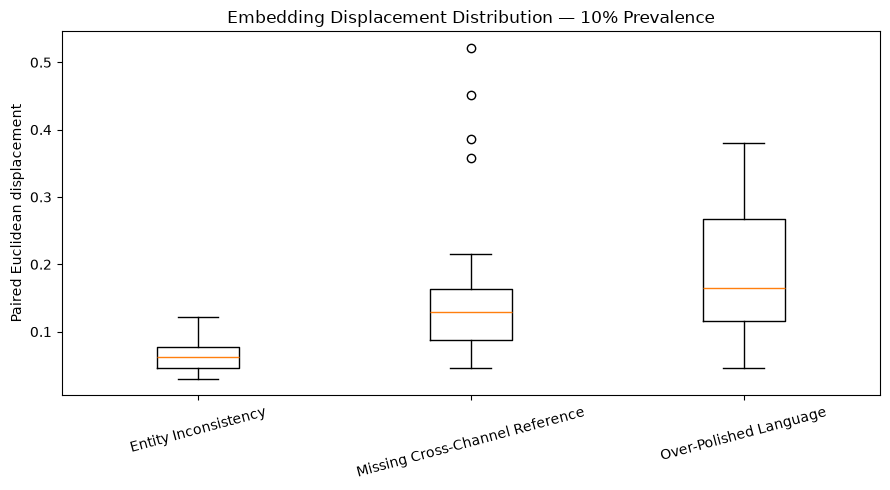

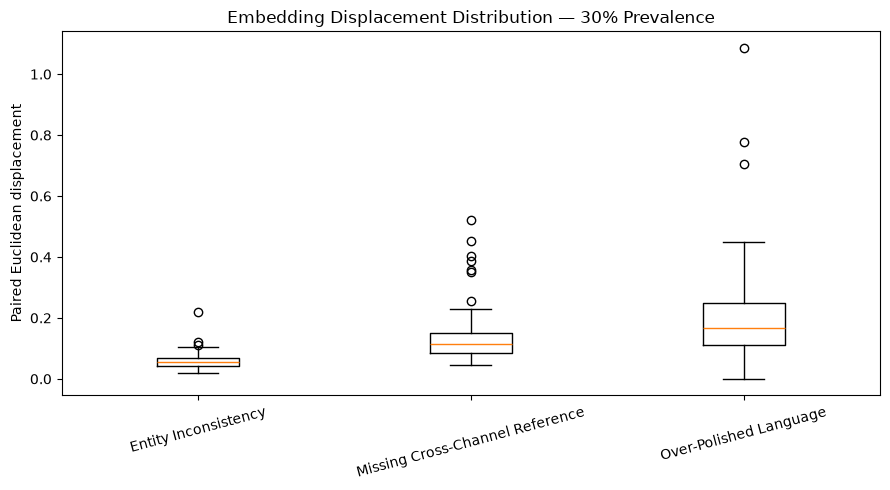

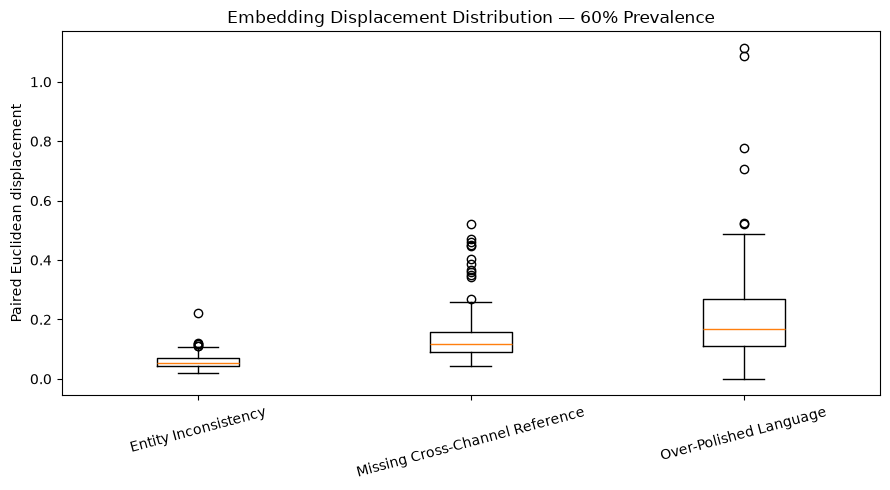

In [55]:
import matplotlib.pyplot as plt


plot_data = (
    embedding_distance_pairwise[
        embedding_distance_pairwise[
            "affected"
        ]
    ]
    .copy()
)


for severity in SEVERITIES:

    subset = (
        plot_data[
            plot_data[
                "severity"
            ]
            ==
            severity
        ]
    )

    grouped = []

    labels = []

    for defect in (
        subset[
            "defect"
        ].unique()
    ):

        distances = (
            subset.loc[
                subset[
                    "defect"
                ]
                ==
                defect,
                "euclidean_distance"
            ]
            .to_numpy()
        )

        grouped.append(
            distances
        )

        labels.append(
            defect
        )


    plt.figure(
        figsize=(9, 5)
    )

    plt.boxplot(grouped, tick_labels=labels)

    plt.ylabel(
        "Paired Euclidean displacement")

    plt.title(
        f"Embedding Displacement "
        f"Distribution — "
        f"{severity:.0%} Prevalence"
    )

    plt.xticks(
        rotation=15
    )

    plt.tight_layout()

    plt.show()

### Embedding Distance Results

Paired embedding-distance analysis confirmed that the representation-level
magnitude of each defect remained approximately stable across prevalence
levels. Entity Inconsistency produced the smallest affected-pair
displacement (approximately 0.06), Missing Cross-Channel Reference produced
an intermediate displacement (approximately 0.14), and Over-Polished
Language produced the largest displacement (approximately 0.19–0.21).
This supports the intended severity design: increasing severity primarily
changes the fraction of affected units rather than the strength of the
individual corruption.

Embedding displacement alone, however, did not predict statistical
detectability. At 10% prevalence, Missing Cross-Channel Reference produced
an average affected-pair displacement of approximately 0.159, more than
twice the displacement produced by Entity Inconsistency (approximately
0.063). Nevertheless, MMD power was only 0.14 for Missing Cross-Channel,
compared with 0.64 for Entity Inconsistency.

This result demonstrates an important distinction between representation
response and distributional detectability. Pairwise distance measures how
far individual observations move from their clean counterparts, but it does
not describe the collective geometry of those movements. Larger but more
heterogeneous perturbations may produce weaker global distributional
separation than smaller but more coherent perturbations.

Over-Polished Language provided a contrasting case: it produced the largest
average displacement and also high MMD and Energy power at low prevalence.
Therefore, large embedding displacement can contribute to detectability,
but displacement magnitude alone is not sufficient to determine statistical
power.

Cosine similarity remained high across all three defects, indicating that
the corrupted observations generally remained close to their clean
counterparts in semantic direction. Because the embeddings are L2-normalized,
cosine similarity and Euclidean displacement are mathematically related and
are treated here as complementary descriptions of the same representation
geometry rather than independent fidelity metrics.

### Validation of the paired design

The analysis used three semantic defects:

- Entity Inconsistency
- Missing Cross-Channel Reference
- Over-Polished Language

Each experiment contained 300 evaluation units and three prevalence conditions: 10%, 30%, and 60%. Entity Inconsistency and Missing Cross-Channel Reference use campaigns as the experimental unit, while Over-Polished Language uses individual SMS messages.

Across all defects and severity levels, the analysis produced 2,700 paired clean/defective observations.


### Representation response

The mean Euclidean displacement among affected pairs was:

| Defect | 10% | 30% | 60% |
|---|---:|---:|---:|
| Entity Inconsistency | 0.0634 | 0.0597 | 0.0585 |
| Missing Cross-Channel Reference | 0.1593 | 0.1370 | 0.1402 |
| Over-Polished Language | 0.1899 | 0.2028 | 0.2066 |

Within each defect, the average displacement remains relatively stable as prevalence increases. This is consistent with the experimental design:
severity changes the proportion of affected units rather than increasing the strength of the corruption applied to each individual unit.

**Important findings by metric**

- **Entity Inconsistency produces the smallest representation change.**
- **Missing Cross-Channel Reference produces a larger change, and**
- **Over-Polished Language produces the largest average displacement.**


### Semantic similarity

Mean cosine similarity remained high for all three defects.

Entity Inconsistency remained extremely close to the clean representation, with cosine similarity around 0.998. Missing Cross-Channel Reference was around 0.981–0.987, while Over-Polished Language remained around 0.966–0.978.

Therefore, even when a defect produced a measurable embedding displacement, the clean and defective observations generally remained close in semantic
direction. This is especially important for Over-Polished Language, where the intended transformation changes linguistic style while preserving most of the message meaning.


### Blind cases

- Entity Inconsistency contained no affected campaigns with zero embedding displacement.

- Missing Cross-Channel Reference also contained no zero-displacement affected cases.

- Over-Polished Language retained legitimate representation-level blind cases. At 30% prevalence, 2 of 90 affected messages produced zero
embedding displacement, and at 60%, 7 of 180 did so. Previous tokenizer inspection showed that these textual changes produced identical token IDs, so the differences disappeared before reaching the semantic encoder.


### Key takeaway: embedding displacement does not determine detection power

The main finding of this analysis is that the magnitude of an individual embedding change does not directly predict the statistical power of a two-sample test.

At 10% prevalence:

| Defect | Mean affected displacement | MMD power | Energy power |
|---|---:|---:|---:|
| Entity Inconsistency | 0.0634 | 0.640 | 0.605 |
| Missing Cross-Channel Reference | 0.1593 | 0.140 | 0.140 |
| Over-Polished Language | 0.1899 | 0.880 | 0.870 |

Missing Cross-Channel Reference produces more than twice the average pairwise displacement of Entity Inconsistency, but its MMD and Energy power are much lower at 10% prevalence. This shows that pairwise displacement and distributional detectability measure different properties.

Pairwise distance measures how far each defective observation moves away from its clean counterpart. A two-sample test instead depends on the collective structure of the entire clean and defective distributions.

Therefore, a larger average movement does not guarantee that the resulting distributional change will be easier to detect.


### Bbehavior by metric


- **Entity Inconsistency**: MMD and Energy Distance reach high power while the linear C2ST remains weak. At 60% prevalence, MMD and Energy both reach power 1.00, while C2ST reaches only 0.165.

- **Missing Cross-Channel Reference:** all three metrics increase with prevalence, but C2ST remains less sensitive than MMD and Energy.

- **Over-Polished Language** C2ST is weak at low prevalence but increases strongly as more messages are affected, reaching 0.93 at 60%. MMD and Energy already have high power at 10% and saturate by 30%.


**Conclusion** 
Embedding distance provides a useful diagnostic for understanding what information the frozen representation preserves before interpreting the behavior of the metrics.

The analysis confirmed that the three defects produce clearly different representation responses, while also showing that larger embedding displacement does not necessarily imply greater statistical detectability.